# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_: Complete all the problems. For the report, include the figures from Problem 2 and 3 and their discussion.
- **Report:** See Problem 2
    - **Figure:** Plot and compare baseline signal and sampled signals, alongside their corresponding FFT magnitude spectra.
    - **Discussion:** Compare the fourier transforms of the sampled signal (sufficently, exactly, vs undersampled)? Given the highest frequency in a signal, what is the resolution/minimum sampling rate required to avoid distortion?  Why does measuring a wave too slowly tricks the system into seeing a lower frequency? (Answer in $3$ sentences)
     
- **Code:** Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle C.
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

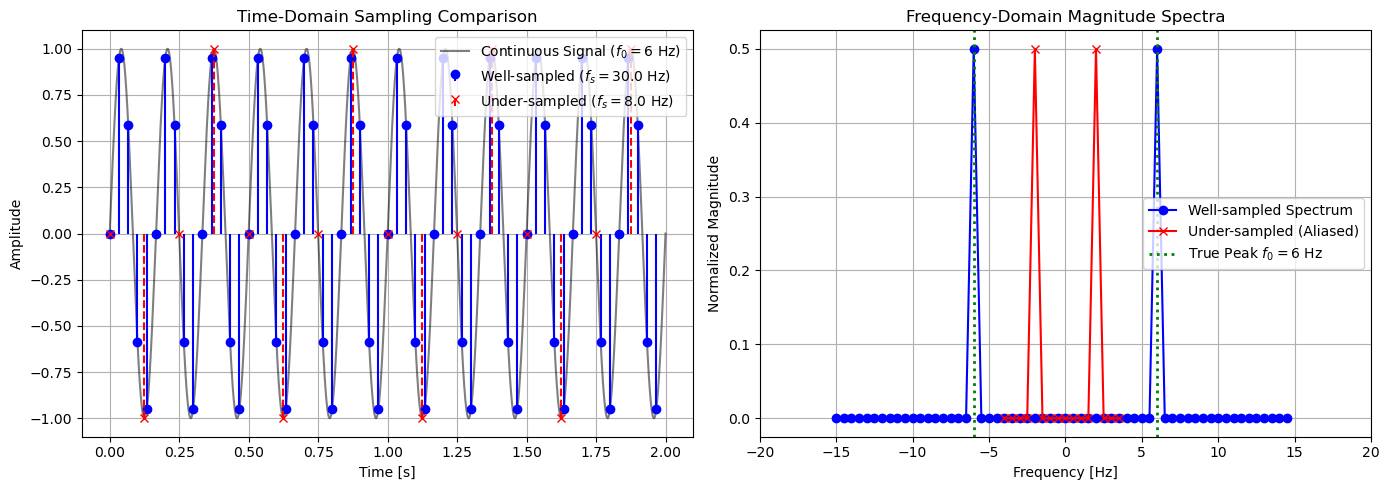

In [17]:
fig2

**Figure 1.** Sampling and aliasing of a sinusoid at 6 Hz. The left plot compares the continuous reference signal with linearly interpolated sample points for sampling rates that exceed the Nyquist rate (30 Hz), exactly at the Nyquist rate (12 Hz), and below it (8 Hz). The right plot compares the corresponding one-sided FFT magnitude spectra. The undersampled signal generates a peak at 2 Hz rather than the actual 6 Hz frequency.


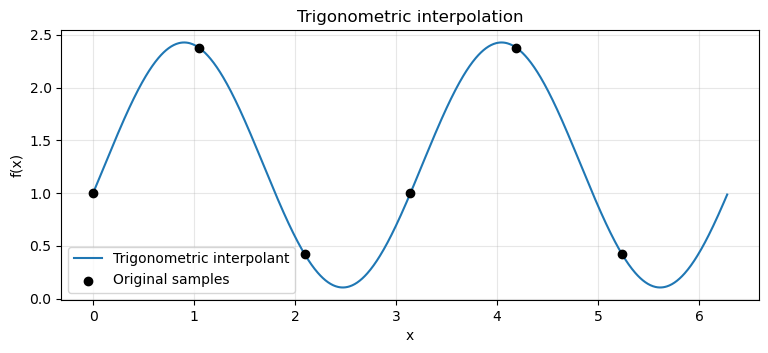

In [36]:
fig3

**Supplementary figure.** The Section 3 example uses six equally spaced samples of $f(x)=e^{\sin(2x)}$ and plots the resulting trigonometric interpolant.

The interpolant generates the six sample values to floating-point precision (maximum node error around $8.9\times10^{-16}$). It provides an approximation of the original function between the sample points. This figure illustrates the trigonometric-interpolation example found in Section 3.


### Report discussion

*(1) Compare the fourier transforms of the sampled signal (sufficently, exactly, vs undersampled)?*
- In the sufficiently sampled range ($f_s = 30$ Hz), the magnitude spectrum of the discrete Fourier transform effectively displays clear, distinct peaks at the actual original signal frequency of $\pm 6$ Hz. Nevertheless, in the case of under-sampling ($f_s = 8$ Hz), the frequency spectrum fails to represent the actual signal. Since the sampling rate is below the Nyquist limit, the peaks repeat across the Nyquist boundary and incorrectly appear as phantom alias peaks at $\pm 2$ Hz.

*(2) Given the highest frequency in a signal, what is the resolution/minimum sampling rate required to avoid distortion?*
- Given the highest frequency component $f_{\text{max}}$ present in a continuous signal, the minimum sampling rate (the Nyquist rate) required to prevent any aliasing distortion must be strictly greater than twice that highest frequency ($f_s > 2f_{\text{max}}$). For our $6$ Hz sine wave, the absolute minimum rate is $12$ Hz.

*(3) Why does measuring a wave too slowly tricks the system into seeing a lower frequency?*
- When a high-frequency wave is sampled at a slow rate, the sampling interval captures less than two points per cycle, completely overlooking the fast intermediate oscillations of the actual wave. As a result, the discrete samples align precisely with a much slower, lower-frequency sinusoidal curve. When the system interpolates or takes the Fourier transform of these sparse data points, it naturally reconstructs this false, low-frequency wave (an alias).

### Other comments
- Answered this right after our Physics 117 exam. T^T.
- I'm not sure po kung typo lang po yung nasa taas na dapat from Problem 2 and 3 yung report figures kasi wala pong Problem 3. Ang in-assume ko na lang po ay kasama yung pinaka-last sa Section 3, which is yung trigonometric interpolation.
- Sorry po, sir. Sobrang sabog na po, pero keri naman kasi medyo repetitive lang yung algorithms. Also had a physics major friend check it. 
- Sana ay kayanin pa sa LE2 ng 155 lec sa Thursday. (Omagoodness hindi ko na kinakaya T^T)
- *insert depressed Shinichi sitting on chair meme*

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed November 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms in the pool below, produce $1\times3$ plots containing the following (for each wave): 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Below each plot, **add 2-3 sentences** explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does its Fourier transform change based on increasing or decreasing sigma?

#### Waveforms:
* Sinusoid (vary frequency and phase), e.g.
$ f(x) = \sin(2\pi fx)$
* Sum of sinusoids (vary f1 and f2) or product of sinusoids, e.g.: $ f(x) = \sin(2\pi f_1 x) + \sin(2\pi f_2 x)$
* Product of sinusoids (vary f1 and f2), e.g. $ f(x) = \sin(2\pi f_1 x) \sin(2\pi f_2 x)$
* Square wave (single/periodic), e.g.:
$ f(x) = \begin{cases} 
1 & \text{if } |x| \le w \\
0 & \text{if } |x| \ge w 
\end{cases}$ or $f(x) = \text{sgn}(\sin(2\pi f_0 x))$
* Triangle wave (sawtooth, ramp, reverse ramp), e.g. $f(x) = 1 - 2\vert{} (f_0 x \bmod 1) - 0.5 \vert{}$ or $f(x) = 2(f_0 x \bmod 1) - 1$ or $f(x) = 1 - 2(f_0 x \bmod 1)$
- Gaussian function (vary sigma), e.g.: $f(x) = e^{-\frac{x^2}{2\sigma^2}}$
- Finite-time sinusoid, e.g. $f(x) = \begin{cases} \sin(2\pi f_0 x), & \vert{}x\vert{} \le \frac{T}{2} \\ 0, & \vert{}x\vert{} > \frac{T}{2} \end{cases}$
- Gaussian wave packet, e.g.: $f(x) = e^{-\frac{x^2}{2\sigma^2}} \cos(2\pi f_0 x)$

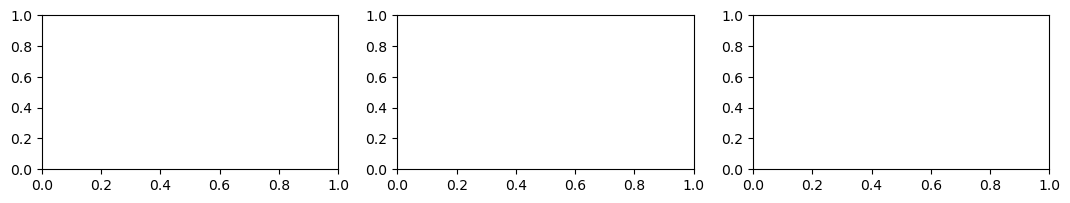

In [2]:
# usual global params
Npts = 1000                     # number of points
deltaT = 0.01                   # [s] sampling interval (sampling Rate is inverse of deltaT = 100 Hz)
t = np.arange(Npts) * deltaT    # temporal points

# f1 = 1.0     # frequency 1 (Hz)
# f2 = 4.0     # frequ?ency 2 (Hz)

# def waveform_something(x, f=1.0):
    # return something

######## SAMPLE PIPELINE ########
# given signal (s) data and time step (dt = 1/fs)
# N = length of signal
# amplitude: np.fft(signal)  ---> shift the result with np.fft.fftshift(...)
# frequency: np.fft.fftfreq(N, d=dt) --> shift the result with np.fft.fftfreq(...)
# phase: np.angle(shifted fft amp) --> unwrap 

# plotting

fig, axes = plt.subplots(1, 3, figsize=(13, 2))

# LEFT: plot signal vs time
# CENTER: plot absolute of shifted amplitude (note it since it is complex in nature) vs shifted frequency
# RIGHT: plot unwrapped phase vs shifted frequency
# make sure to add axes labels and title

# see section 3 plotting notes for the structure
# the goal here is to familiarize with how `np.fft` works and what do they mean when applied on waves

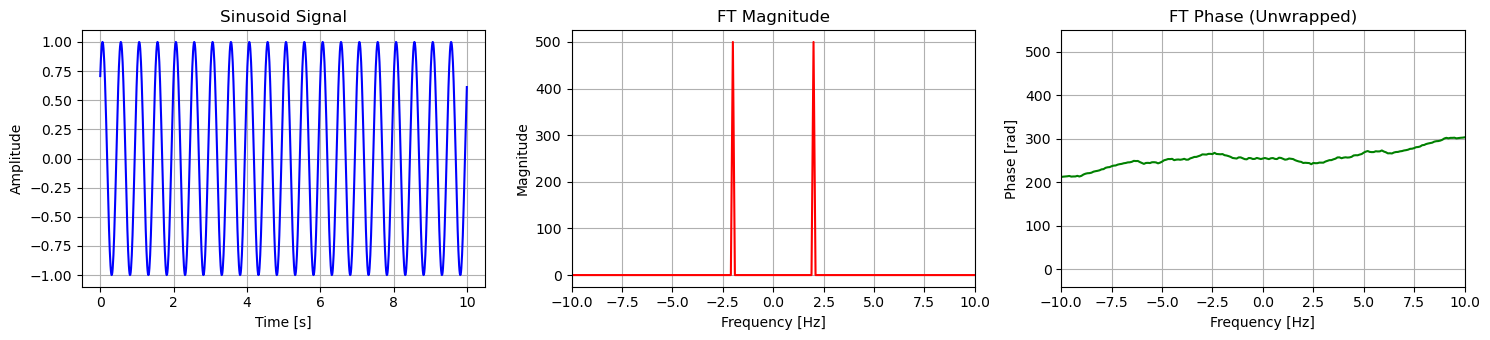

In [2]:
# sinusoids

Npts = 1000
deltaT = 0.01
t = np.arange(Npts) * deltaT
fs = 1.0 / deltaT

f_val = 2.0
phase_val = np.pi / 4
sig = np.sin(2 * np.pi * f_val * t + phase_val)

# FFT
freqs = np.fft.fftfreq(Npts, d=deltaT)
fft_val = np.fft.fft(sig)

# Shift
freqs_shifted = np.fft.fftshift(freqs)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t, sig, 'b-')
axes[0].set_title('Sinusoid Signal')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-10, 10)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-10, 10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** Increasing the sinusoid frequency shifts the two primary FFT peaks further from zero frequency. Changing the phase shifts the wave in time and changes the FFT phase, but it does not affect the locations or amplitudes of the frequency peaks. 


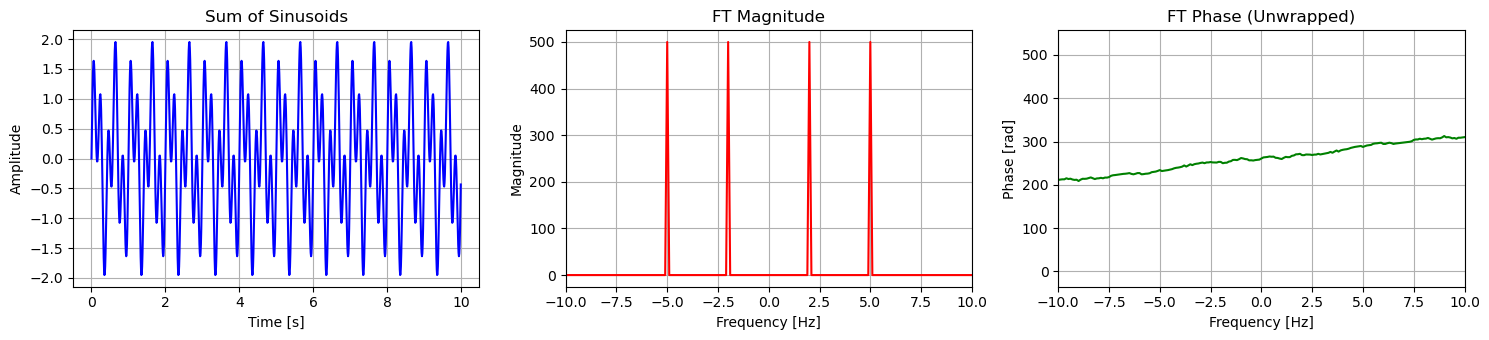

In [3]:
# sum of sinusoids

f1, f2 = 2.0, 5.0
sig = np.sin(2 * np.pi * f1 * t) + np.sin(2 * np.pi * f2 * t)

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t, sig, 'b-')
axes[0].set_title('Sum of Sinusoids')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-10, 10)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-10, 10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** A sum of two sinusoids results in a pair of positive-frequency and negative-frequency peaks for each component. Since $(f_1)$ remains constant, its peaks remain stationary, while changing $(f_2)$ shifts the other pair.


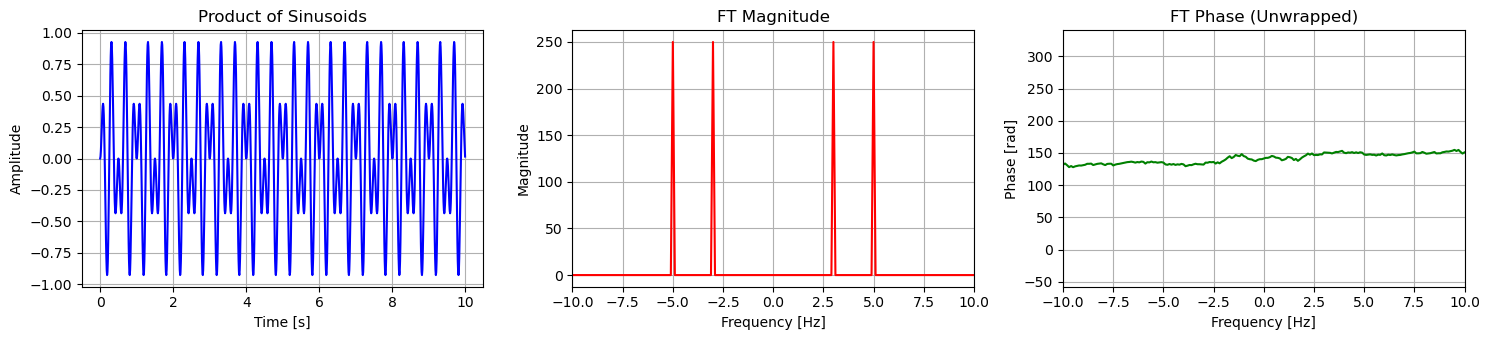

In [4]:
# product of sinusoids

f1, f2 = 1.0, 4.0
sig = np.sin(2 * np.pi * f1 * t) * np.sin(2 * np.pi * f2 * t)

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t, sig, 'b-')
axes[0].set_title('Product of Sinusoids')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-10, 10)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-10, 10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** The product identity $\sin(2\pi f_1t)\sin(2\pi f_2t)=\tfrac12[\cos(2\pi(f_1-f_2)t)-\cos(2\pi(f_1+f_2)t)]$ indicates that there will be peaks at the frequencies of the difference and sum. Changing $(f_2)$ shifts both spectral elements.


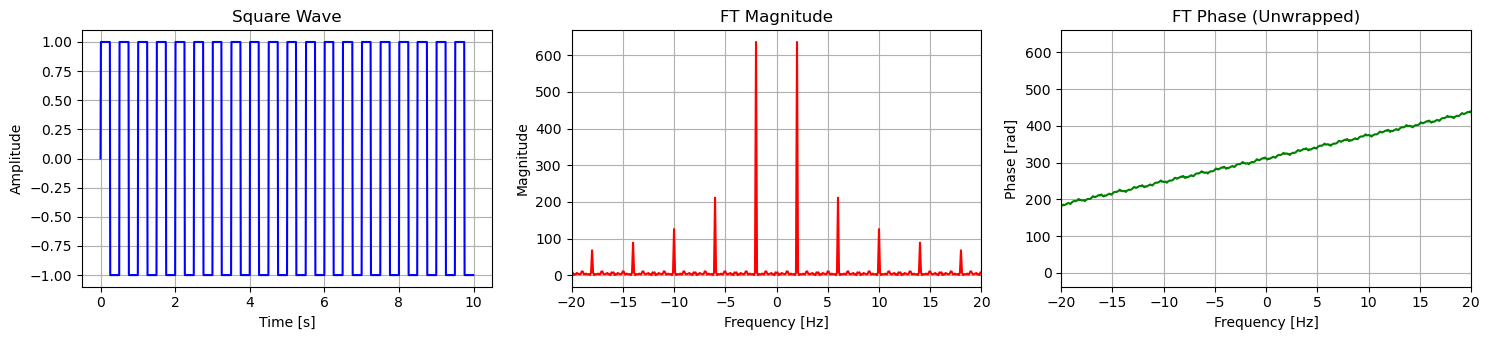

In [5]:
# square wave

f0 = 2.0
sig = np.sign(np.sin(2 * np.pi * f0 * t))

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t, sig, 'b-')
axes[0].set_title('Square Wave')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-20, 20)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-20, 20)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** A square wave consists of the fundamental frequency and odd harmonics, with the amplitudes of the harmonics decreasing approximately as $(1/n)$. Increasing the fundamental frequency widens the gaps between these harmonic peaks. 


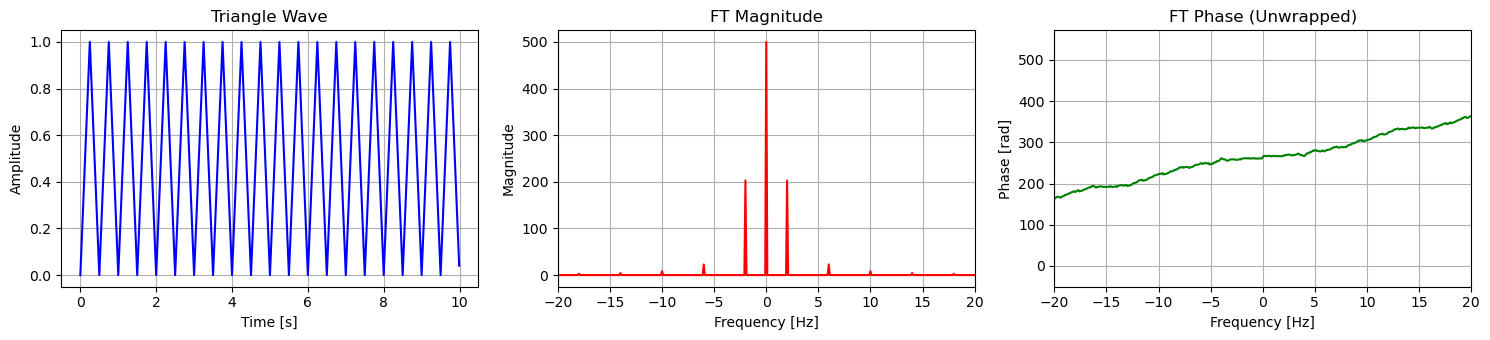

In [6]:
# triangle wave

f0 = 2.0
sig = 1.0 - 2.0 * np.abs((f0 * t % 1.0) - 0.5)

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t, sig, 'b-')
axes[0].set_title('Triangle Wave')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-20, 20)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-20, 20)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** A triangle wave also contains odd harmonics, but their amplitudes decrease approximately as $(1/n^2)$. Its smoother corners consequently generate much less high-frequency content compared to a square wave with the same fundamental frequency.


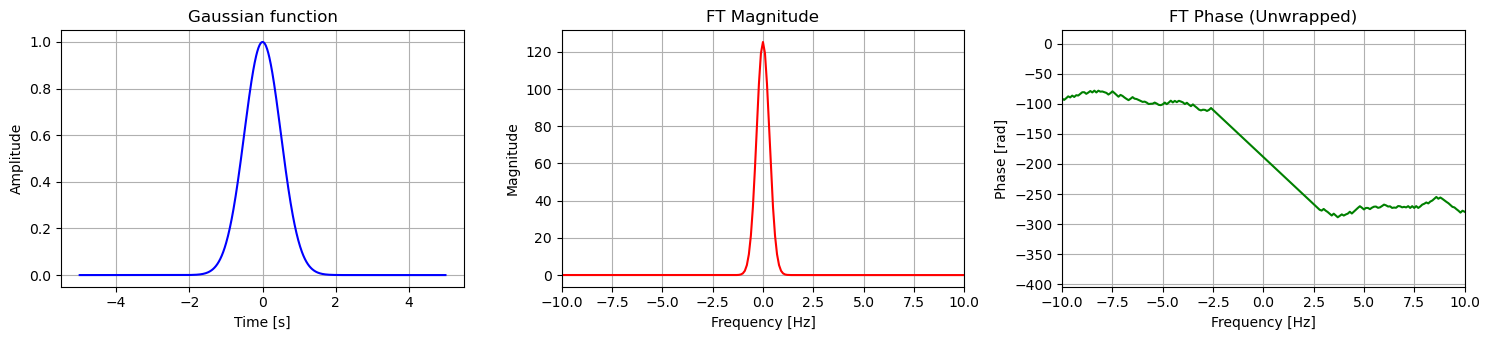

In [7]:
# gaussian function

t_centered = t - np.mean(t)
sigma = 0.5
sig = np.exp(-t_centered**2 / (2 * sigma**2))

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t_centered, sig, 'b-')
axes[0].set_title('Gaussian function')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-10, 10)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-10, 10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** Increasing $(\sigma)$ makes the Gaussian wider in time and narrower in frequency. Decreasing $(\sigma)$ results in a narrower time-domain pulse with an expanded Fourier spectrum, illustrating the time-frequency balance.


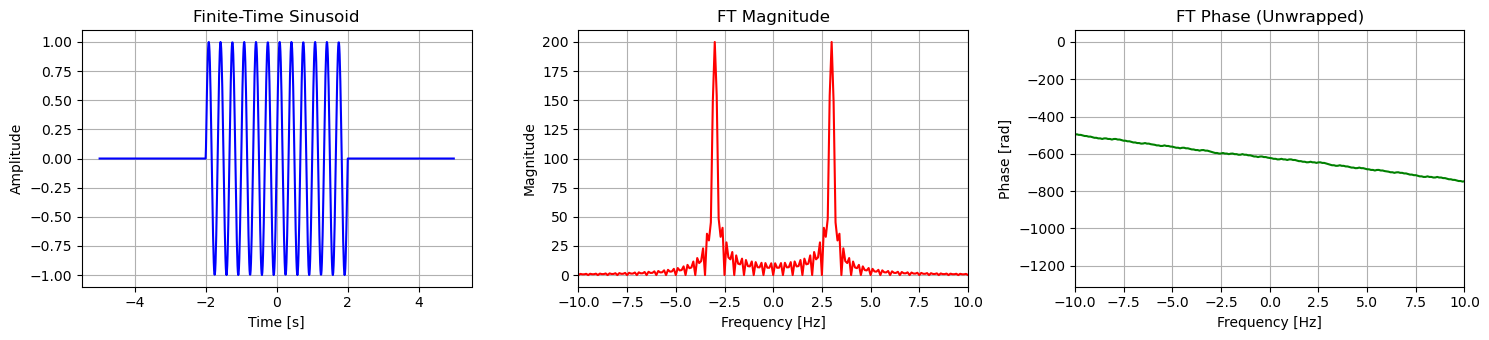

In [8]:
# finite time sinusoid

f0 = 3.0
T_window = 4.0
sig = np.zeros_like(t)
t_centered = t - np.mean(t)
mask = np.abs(t_centered) <= (T_window / 2.0)
sig[mask] = np.sin(2 * np.pi * f0 * t_centered[mask])

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t_centered, sig, 'b-')
axes[0].set_title('Finite-Time Sinusoid')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-10, 10)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-10, 10)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** Restricting a sinusoid to a finite time interval disperses its energy over a range of frequencies instead of producing infinitely sharp spectral lines. A longer time frame narrows the primary spectral lobe, while a shorter frames expands it. 


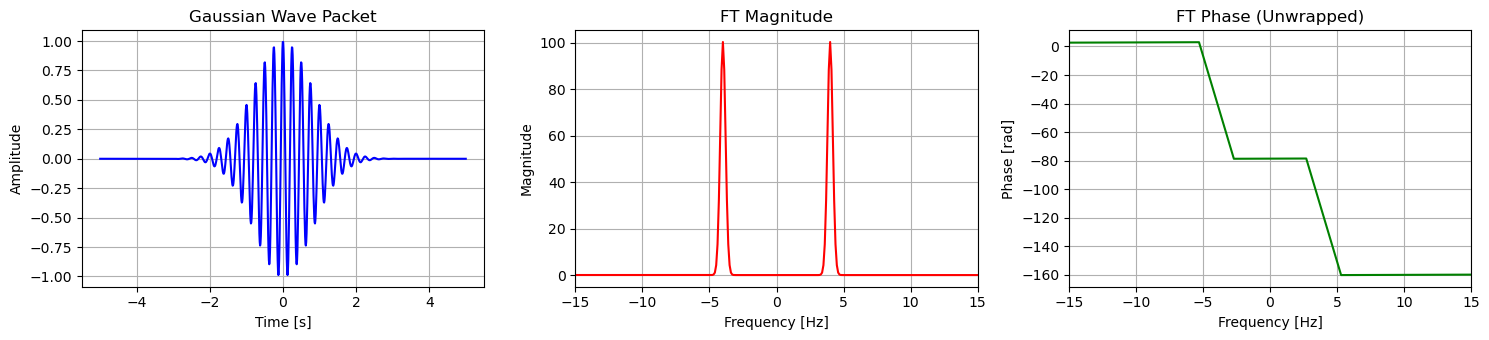

In [10]:
# gaussian wave packet

t_centered = t - np.mean(t)
sigma = 0.8
f0 = 4.0
sig = np.exp(-t_centered**2 / (2 * sigma**2)) * np.cos(2 * np.pi * f0 * t_centered)

fft_val = np.fft.fft(sig)
fft_shifted = np.fft.fftshift(fft_val)
mag_spectrum = np.abs(fft_shifted)
phase_spectrum = np.unwrap(np.angle(fft_shifted))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(t_centered, sig, 'b-')
axes[0].set_title('Gaussian Wave Packet')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True)

axes[1].plot(freqs_shifted, mag_spectrum, 'r-')
axes[1].set_title('FT Magnitude')
axes[1].set_xlabel('Frequency [Hz]')
axes[1].set_ylabel('Magnitude')
axes[1].set_xlim(-15, 15)
axes[1].grid(True)

axes[2].plot(freqs_shifted, phase_spectrum, 'g-')
axes[2].set_title('FT Phase (Unwrapped)')
axes[2].set_xlabel('Frequency [Hz]')
axes[2].set_ylabel('Phase [rad]')
axes[2].set_xlim(-15, 15)
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Interpretation.** The cosine carrier generates spectral peaks at $(+f_0)$ and $(-f_0)$, while the Gaussian envelope controls their bandwidth. Increasing $(\sigma)$ lengthens the packet and narrows the peaks. A shorter packet has a wider spectrum. 


#### Problem 1 code summary

This script utilizes numpy's fast Fourier transform module (`np.fft`) to analyze eight fundamental waveforms. By plotting each time-domain signal next to its shifted magnitude spectrum and unwrapped phase spectrum, we can easily observe how the variations in waveshape, frequency, and phase transformations are represented to the frequency domain.


### Problem 2: Shannon-Nyquist sampling theorem and aliasing
1. Specify a fixed target frequency $f_0$, duration, and amplitude. Generate a sine wave using those parameters.
2. Create a sampled wave. Keep the original signal frequency $f_0$ constant. To sample the wave, do not change $f_0$ inside the sine function. Instead, create a discrete time vector `t_samp`$=[0, \text{duration}]$  using a step size of $\Delta t = \frac{1}{f_s}$.
3. Evaluate your wave at these discrete sample points using $x_{\text{samp}} = \text{amplitude} \cdot \sin(2\pi f_0 \, \texttt{t\_samp})$ across the three required regimes:
    - Well-Sampled Rate ($f_{s,\text{high}} > 2f_0$): Sample well above the Nyquist rate to accurately capture the waveform (e.g., $f_s = 30\text{ Hz}$ for a $6\text{ Hz}$ wave).
    - Exact Nyquist Limit ($f_{s,\text{Nyquist}} = 2f_0$): Sample at exactly twice the signal frequency (e.g., $f_s = 12\text{ Hz}$ for a $6\text{ Hz}$ wave).
    - Under-Sampled Rate ($f_{s,\text{low}} < 2f_0$): Sample below the Nyquist rate to induce aliasing (e.g., $f_s = 8\text{ Hz}$ for a $6\text{ Hz}$ wave).
4. Compute the discreet Fourier transform (FFT) of both discrete signals ($x_{\text{correct}}[n]$ and $x_{\text{aliased}}[n]$)
5. Compare the detected peak frequencies in the **magnitude spectra** of both sampled signals against the true frequency $f_0$

**[REPORT FIGURE]**
- Generate a $1\times 2$ plot.
- Left is time-Domain Comparison: plot the true continuous baseline signal $x(t)$ alongside the reconstructed waveforms resulting from both sampling rates ($f_{s,\text{high}}$ and $f_{s,\text{low}}$).
- Right is frequency-Domain Comparison: plot the magnitude spectra $|X(f)|$ for both sampled signals, marking the true peak location $f_0$ and any shifted (aliased) spectral peaks.

**[REPORT DISCUSSION]**
- Explain the report figure and the Nyquist theorem. Given the highest frequency in my signal, what is the minimum sampling rate required to avoid distortion? Compare the fourier transforms of the sampled signal (sufficently vs undersampled)? Why does measuring a wave too slowly tricks the system into seeing a lower frequency? (Answer in $3$ sentences)

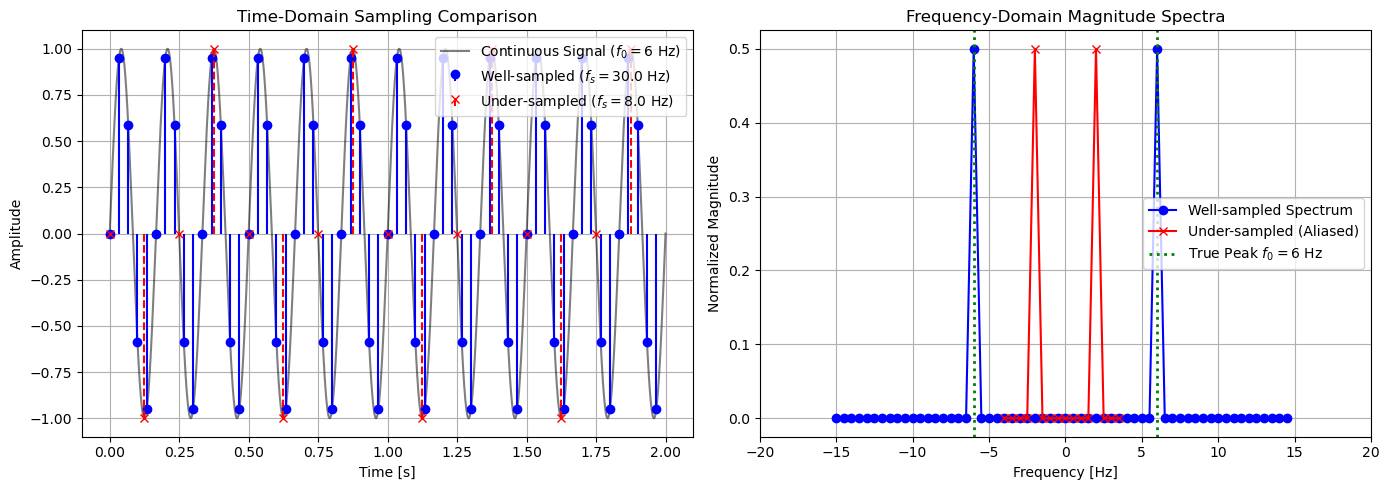

In [15]:
# Parameters
f0 = 6.0          # Target frequency (Hz)
duration = 2.0    # Duration (s)
amp = 1.0         # Amplitude

# Continuous baseline representation
t_cont = np.linspace(0, duration, 2000)
x_cont = amp * np.sin(2 * np.pi * f0 * t_cont)

# Sampling frequencies
fs_high = 30.0   # Well-sampled
fs_nyq = 12.0    # Exact Nyquist
fs_low = 8.0     # Under-sampled

# Discrete time vectors
t_high = np.arange(0, duration, 1.0 / fs_high)
t_nyq = np.arange(0, duration, 1.0 / fs_nyq)
t_low = np.arange(0, duration, 1.0 / fs_low)

# Sampled signals
x_high = amp * np.sin(2 * np.pi * f0 * t_high)
x_nyq = amp * np.sin(2 * np.pi * f0 * t_nyq)
x_low = amp * np.sin(2 * np.pi * f0 * t_low)

# FFT computations
fft_high = np.fft.fftshift(np.fft.fft(x_high))
freq_high = np.fft.fftshift(np.fft.fftfreq(len(x_high), 1.0 / fs_high))

fft_low = np.fft.fftshift(np.fft.fft(x_low))
freq_low = np.fft.fftshift(np.fft.fftfreq(len(x_low), 1.0 / fs_low))

# Plotting 1x2 comparison
fig2, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: Time Domain
ax[0].plot(t_cont, x_cont, 'k-', label='Continuous Signal ($f_0 = 6$ Hz)', alpha=0.5)
ax[0].stem(t_high, x_high, 'b', linefmt='b-', markerfmt='bo', basefmt=' ', label=f'Well-sampled ($f_s = {fs_high}$ Hz)')
ax[0].stem(t_low, x_low, 'r', linefmt='r--', markerfmt='rx', basefmt=' ', label=f'Under-sampled ($f_s = {fs_low}$ Hz)')
ax[0].set_title('Time-Domain Sampling Comparison')
ax[0].set_xlabel('Time [s]')
ax[0].set_ylabel('Amplitude')
ax[0].legend(loc='upper right')
ax[0].grid(True)

# Right: Frequency Domain
ax[1].plot(freq_high, np.abs(fft_high) / len(x_high), 'b-o', label='Well-sampled Spectrum')
ax[1].plot(freq_low, np.abs(fft_low) / len(x_low), 'r-x', label='Under-sampled (Aliased)')
ax[1].axvline(f0, color='g', linestyle=':', label='True Peak $f_0 = 6$ Hz', linewidth=2)
ax[1].axvline(-f0, color='g', linestyle=':', linewidth=2)
ax[1].set_title('Frequency-Domain Magnitude Spectra')
ax[1].set_xlabel('Frequency [Hz]')
ax[1].set_ylabel('Normalized Magnitude')
ax[1].set_xlim(-20, 20)
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

#### Problem 2 code summary

This script compares a 6 Hz sinusoidal signal sampled at various frequencies to demonstrate how sampling rates affect signal representation and reveal aliasing in the frequency domain. It uses a continuous reference, discrete sampling, and normalized FFT spectra to demonstrate the differences between well-sampled and under-sampled signals, making the Nyquist criterion and the resulting frequency alias easier to understand.

---
## Section 3: Notes

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

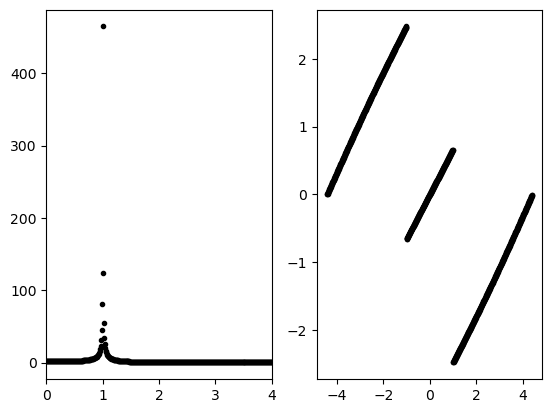

In [23]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

Text(0, 0.5, 'x')

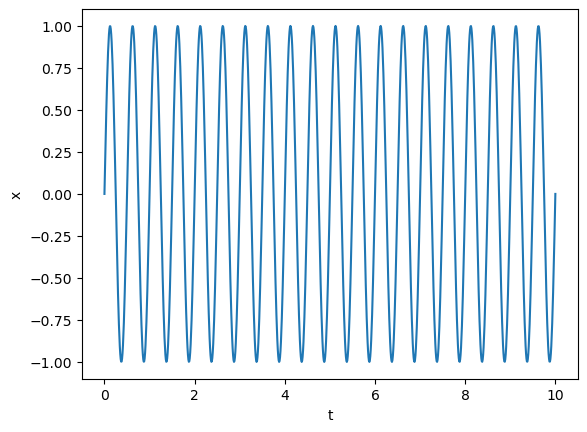

In [24]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [25]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

In [15]:
np.fft.fftshift?

Signature: np.fft.fftshift(x, axes=None)
Docstring:
Shift the zero-frequency component to the center of the spectrum.

This function swaps half-spaces for all axes listed (defaults to all).
Note that ``y[0]`` is the Nyquist component only if ``len(x)`` is even.

Parameters
----------
x : array_like
    Input array.
axes : int or shape tuple, optional
    Axes over which to shift.  Default is None, which shifts all axes.

Returns
-------
y : ndarray
    The shifted array.

See Also
--------
ifftshift : The inverse of `fftshift`.

Examples
--------
>>> freqs = np.fft.fftfreq(10, 0.1)
>>> freqs
array([ 0.,  1.,  2., ..., -3., -2., -1.])
>>> np.fft.fftshift(freqs)
array([-5., -4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.])

Shift the zero-frequency component only along the second axis:

>>> freqs = np.fft.fftfreq(9, d=1./9).reshape(3, 3)
>>> freqs
array([[ 0.,  1.,  2.],
       [ 3.,  4., -4.],
       [-3., -2., -1.]])
>>> np.fft.fftshift(freqs, axes=(1,))
array([[ 2.,  0.,  1.],
       [-4.

### Plotting

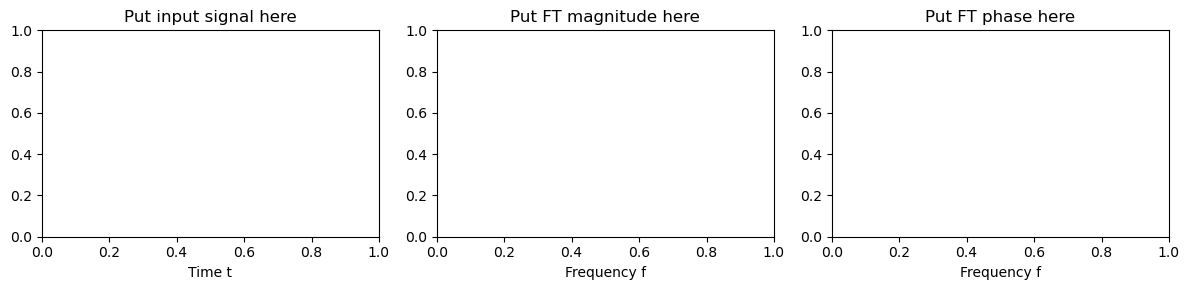

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

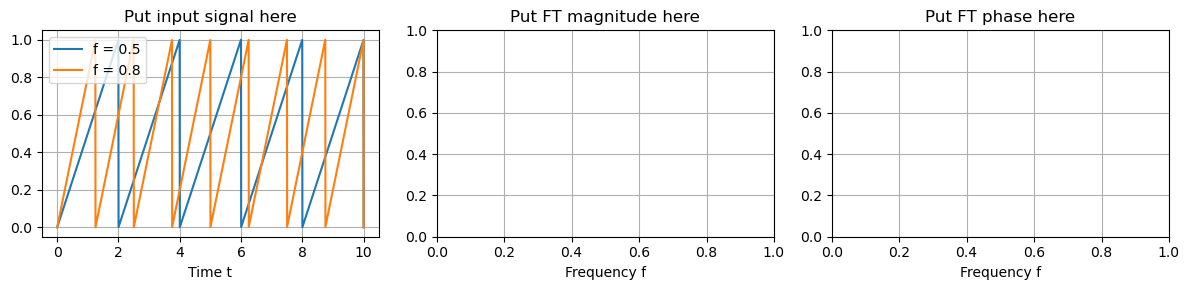

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

### Others: Trigonometric interpolation (Approximation)

In [31]:
def f(x):
    """Function sampled for the trigonometric-interpolation example."""
    return np.exp(np.sin(2 * x))


def generatedata(n, function):
    """Return n equally spaced samples on [0, 2*pi), for even n."""
    if not isinstance(n, (int, np.integer)) or n < 4 or n % 2:
        raise ValueError("n must be an even integer greater than or equal to 4")
    data_x = 2 * np.pi * np.arange(n) / n
    data_y = np.asarray(function(data_x), dtype=float)
    if data_y.shape != data_x.shape:
        raise ValueError("function must return one value for each input point")
    return data_x, data_y


def computeparams(data_x, data_y):
    """Compute cosine and sine coefficients for even-length samples."""
    data_x = np.asarray(data_x, dtype=float)
    data_y = np.asarray(data_y, dtype=float)
    if data_x.ndim != 1 or data_y.ndim != 1 or data_x.size != data_y.size:
        raise ValueError("data_x and data_y must be one-dimensional arrays of equal size")
    n = data_x.size
    if n < 4 or n % 2:
        raise ValueError("the number of data points must be even and at least 4")

    m = n // 2
    cosine_harmonics = np.arange(m + 1)[:, None]
    sine_harmonics = np.arange(1, m)[:, None]
    a_params = np.cos(cosine_harmonics * data_x) @ data_y / m
    b_params = np.sin(sine_harmonics * data_x) @ data_y / m
    return a_params, b_params


def triginterp(a_params, b_params, x):
    """Evaluate the even-sample trigonometric interpolant at scalar or array x."""
    a_params = np.asarray(a_params, dtype=float)
    b_params = np.asarray(b_params, dtype=float)
    if a_params.ndim != 1 or b_params.ndim != 1:
        raise ValueError("coefficient arrays must be one-dimensional")
    m = a_params.size - 1
    if m < 2 or b_params.size != m - 1:
        raise ValueError("incompatible cosine and sine coefficient arrays")

    x = np.asarray(x, dtype=float)
    result = 0.5 * (a_params[0] + a_params[-1] * np.cos(m * x))
    if m > 1:
        harmonics = np.arange(1, m)
        cosine_terms = np.cos(np.multiply.outer(harmonics, x))
        sine_terms = np.sin(np.multiply.outer(harmonics, x))
        result = result + np.tensordot(a_params[1:m], cosine_terms, axes=(0, 0))
        result = result + np.tensordot(b_params, sine_terms, axes=(0, 0))
    return result

In [34]:
# Evaluate the interpolant at one point.
data_x, data_y = generatedata(6, f)
a_params, b_params = computeparams(data_x, data_y)
x_value = 0.3
interpolated_value = triginterp(a_params, b_params, x_value)
print(f"x = {x_value:.3f}, interpolated f(x) = {interpolated_value:.8f}")

x = 0.300, interpolated f(x) = 1.68438168


Maximum interpolation error at sample nodes: 8.882e-16


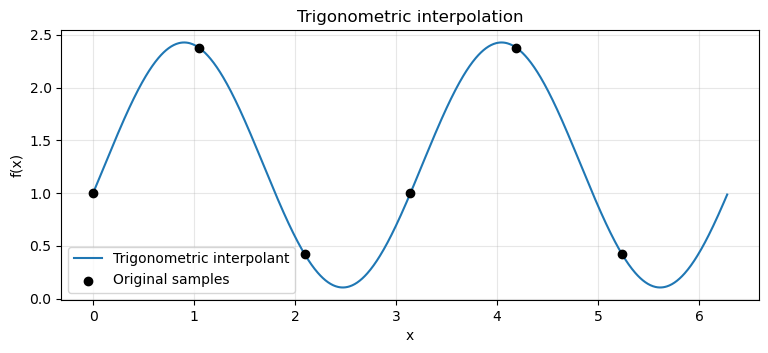

In [35]:
# Check that the trigonometric interpolant reproduces all sample values.
x_dense = np.linspace(0.0, 2 * np.pi, 1000, endpoint=False)
y_dense = triginterp(a_params, b_params, x_dense)
y_at_nodes = triginterp(a_params, b_params, data_x)
max_node_error = np.max(np.abs(y_at_nodes - data_y))
print(f"Maximum interpolation error at sample nodes: {max_node_error:.3e}")

fig3, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(x_dense, y_dense, label="Trigonometric interpolant")
ax.scatter(data_x, data_y, color="black", zorder=3, label="Original samples")
ax.set(title="Trigonometric interpolation", xlabel="x", ylabel="f(x)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

plt.show()